# 08 – Final test: the test year 2025-26
**7PAM2033 Team 18 · Next-day GB thermal constraint volume forecasting**

The three best models from the validation year (Chronos, LSTM tuned, Hybrid tuned) and persistence are scored **once** on the test year, which no model or tuning step has seen. These are the final results for the report.

The saved models are loaded, not retrained. Run this notebook only once.

**Test, Step 1: Load the data**

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from chronos import BaseChronosPipeline

from src.config import ROOT, load_config
from src.features.build_features import split_by_date
from src.models.baselines import persistence
from src.evaluation.metrics import diebold_mariano, mae, rmse
from src.models.lstm import (DEFAULT_FEATURES, LSTMRegressor, Scaler, make_sequences, make_target,
                             predict, prepare_inputs, recent_level)

cfg = load_config()
tables = sorted((ROOT / "data" / "processed").glob("daily_model_table_*.parquet"))
table = pd.read_parquet(tables[-1]).asfreq("D")
parts = split_by_date(table, cfg["split"])
train_idx, test_idx = parts["train"].index, parts["test"].index
target = table["target"]
pers_all = persistence(target)
print(table.shape[0], "days loaded | test year:", test_idx.min().date(), "to", test_idx.max().date())
print("Days in the test year with no data:", int(target.loc[test_idx].isna().sum()))

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1029 14:13:22.258000 2400 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


3481 days loaded | test year: 2025-04-02 to 2026-03-31
Days in the test year with no data: 1


**Test, Step 2: LSTM tuned forecasts** (model saved in notebook 06)

In [3]:
# Rebuild the inputs exactly as in notebook 06 (scaler fitted on the training years only)
x_all = prepare_inputs(table, DEFAULT_FEATURES, relative=True)
y_log = make_target(table, relative=True)
level_all = recent_level(table)
scaler = Scaler.fit(x_all.loc[train_idx])
x_scaled = scaler.transform(x_all.ffill(limit=2))   # carry yesterday's value over the one missing day
y_mean, y_std = float(y_log.loc[train_idx].mean()), float(y_log.loc[train_idx].std())
y_scaled = (y_log - y_mean) / y_std

# Load the tuned LSTM saved in notebook 06 (no retraining)
saved = torch.load(ROOT / "models" / "lstm_tuned_v2.pt", weights_only=False)
c = saved["config"]
lstm_model = LSTMRegressor(len(DEFAULT_FEATURES), c["hidden"], c["layers"], c["dropout"])
lstm_model.load_state_dict(saved["state_dict"])

Xte, _, d_te = make_sequences(x_scaled, y_scaled, test_idx, c["window"])
lstm_test = pd.Series(predict(lstm_model, Xte, y_mean, y_std, level_all.loc[d_te].to_numpy()), index=d_te)
print("LSTM tuned: forecasts for", len(lstm_test), "test days")

LSTM tuned: forecasts for 363 test days


**Test, Step 3: Hybrid tuned forecasts** (SARIMAX refitted on the training years, LSTM part saved in notebook 07)

In [4]:
# SARIMAX: fitted on the training years only, exactly as in notebooks 03 and 07
y_log_h = np.log1p(target)
exog = table[["wind_mean_mw_lag1", "is_weekend", "is_bank_holiday"]].ffill().bfill()
exog = (exog - exog.loc[train_idx].mean()) / exog.loc[train_idx].std()
res = SARIMAX(y_log_h.loc[train_idx], exog=exog.loc[train_idx],
              order=(1, 1, 1), seasonal_order=(1, 0, 1, 7)).fit(disp=False)
sx_log = res.apply(y_log_h, exog=exog).predict()

# LSTM part inputs: features + SARIMAX's mistakes
resid = y_log_h - sx_log
resid.iloc[:30] = np.nan
xh = prepare_inputs(table, DEFAULT_FEATURES, relative=True)
xh["sarimax_resid_lag1"] = resid.shift(1)
xh["sarimax_vs_level"] = sx_log - recent_level(table)
scaler_h = Scaler.fit(xh.loc[train_idx])
xh_scaled = scaler_h.transform(xh.ffill(limit=2))
r_mean, r_std = float(resid.loc[train_idx].mean()), float(resid.loc[train_idx].std())
r_scaled = (resid - r_mean) / r_std

# Load the tuned hybrid LSTM saved in notebook 07 (no retraining)
best_h = json.loads((ROOT / "results" / "hybrid_tuned_best_params.json").read_text())
hyb_model = LSTMRegressor(xh.shape[1], best_h["hidden"], best_h["layers"], best_h["dropout"])
hyb_model.load_state_dict(torch.load(ROOT / "models" / "hybrid_lstm_tuned_v2.pt"))

Xh, _, dh = make_sequences(xh_scaled, r_scaled, test_idx, best_h["window"])
hybrid_test = pd.Series(predict(hyb_model, Xh, r_mean, r_std, sx_log.loc[dh].to_numpy()), index=dh)
print("Hybrid tuned: forecasts for", len(hybrid_test), "test days")

Hybrid tuned: forecasts for 363 test days


**Test, Step 4: Chronos forecasts** (zero-shot, about 1–3 minutes)

In [6]:
pipeline = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small",
                                               device_map="cpu", torch_dtype=torch.float32)
contexts = [torch.tensor(target.loc[:day - pd.Timedelta(days=1)].tail(512).values, dtype=torch.float32)
            for day in test_idx]
q, _ = pipeline.predict_quantiles(contexts, prediction_length=1, quantile_levels=[0.1, 0.5, 0.9])
chronos_test = pd.Series(q[:, 0, 1].numpy(), index=test_idx).clip(lower=0)
chr_low = pd.Series(q[:, 0, 0].numpy(), index=test_idx).clip(lower=0)
chr_high = pd.Series(q[:, 0, 2].numpy(), index=test_idx)
print("Chronos: forecasts for", len(chronos_test), "test days")

Loading weights: 100%|████████████████████████████████████████████████████████████| 143/143 [00:00<00:00, 10547.35it/s]


Chronos: forecasts for 364 test days


**Test, Step 5: Final scores**

vs_persistence_% above 0 = better than persistence (KPI: +10% or more). DM_p below 0.05 = significant difference.

In [7]:
test_preds = pd.DataFrame({
    "actual": target.loc[test_idx],
    "persistence": pers_all.loc[test_idx],
    "LSTM tuned": lstm_test,
    "Hybrid tuned": hybrid_test,
    "Chronos": chronos_test,
}).dropna()
print(len(test_preds), "test days where every model has a forecast")

actual, pers = test_preds["actual"], test_preds["persistence"]
rows = []
for name in ["persistence", "LSTM tuned", "Hybrid tuned", "Chronos"]:
    p = test_preds[name]
    stat, pval = diebold_mariano(actual, p, pers)
    rows.append({"model": name,
                 "MAE_MWh": round(mae(actual, p), 1),
                 "RMSE_MWh": round(rmse(actual, p), 1),
                 "vs_persistence_%": round(100 * (1 - mae(actual, p) / mae(actual, pers)), 1),
                 "DM_p": None if name == "persistence" else round(pval, 4)})
test_scores = pd.DataFrame(rows).sort_values("MAE_MWh").reset_index(drop=True)

inside = ((actual >= chr_low.loc[actual.index]) & (actual <= chr_high.loc[actual.index])).mean()
print(f"Chronos 10%-90% band contains the actual value on {inside:.0%} of test days (ideal about 80%)")
test_scores

362 test days where every model has a forecast
Chronos 10%-90% band contains the actual value on 83% of test days (ideal about 80%)


,model,MAE_MWh,RMSE_MWh,vs_persistence_%,DM_p
0,Chronos,23683.8,29988.2,2.8,0.4314
1,persistence,24377.3,32677.3,0.0,NaN
2,Hybrid tuned,24730.8,33339.0,-1.5,0.7454
3,LSTM tuned,25319.9,33998.4,-3.9,0.4372


**Test, Step 6: Chart of the final scores**

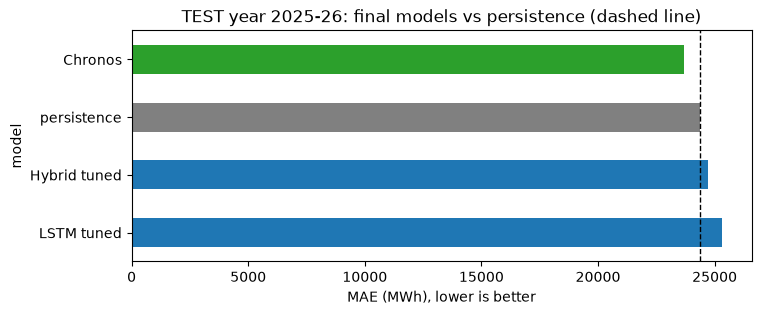

In [8]:
c = test_scores.sort_values("MAE_MWh")
colors = ["tab:green" if m == "Chronos" else "grey" if m == "persistence" else "tab:blue" for m in c["model"]]
ax = c.plot(kind="barh", x="model", y="MAE_MWh", color=colors, legend=False, figsize=(8, 3))
ax.axvline(c.loc[c["model"] == "persistence", "MAE_MWh"].iloc[0], color="black", ls="--", lw=1)
ax.invert_yaxis()
ax.set_xlabel("MAE (MWh), lower is better")
ax.set_title("TEST year 2025-26: final models vs persistence (dashed line)")
plt.show()

**Test, Step 7: Average error by month**

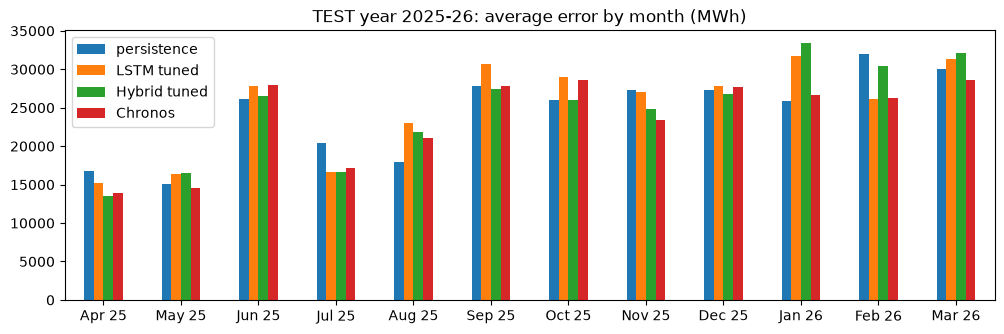

In [9]:
monthly = pd.DataFrame({m: (actual - test_preds[m]).abs()
                        for m in ["persistence", "LSTM tuned", "Hybrid tuned", "Chronos"]}).resample("MS").mean()
monthly.index = monthly.index.strftime("%b %y")
monthly.plot(kind="bar", figsize=(12, 3.5), rot=0, title="TEST year 2025-26: average error by month (MWh)")
plt.show()

**Test, Step 8: Save the final results**

In [10]:
results = ROOT / "results"
test_preds.to_csv(results / "test_predictions.csv")
test_scores.to_csv(results / "test_metrics_final.csv", index=False)
print("Saved: results/test_predictions.csv and results/test_metrics_final.csv")

Saved: results/test_predictions.csv and results/test_metrics_final.csv


In [1]:
# ===== Test, Step 9: Add MASE to the final results =====
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
from src.config import ROOT, load_config
from src.features.build_features import split_by_date
from src.evaluation.metrics import mase

# Read the saved results (no models are run again, so the test year stays used only once)
results = ROOT / "results"
test_preds = pd.read_csv(results / "test_predictions.csv", index_col=0, parse_dates=True)
test_scores = pd.read_csv(results / "test_metrics_final.csv")

# MASE scale = average day-to-day change in the training years (2017-2024)
cfg = load_config()
tables = sorted((ROOT / "data" / "processed").glob("daily_model_table_*.parquet"))
table = pd.read_parquet(tables[-1]).asfreq("D")
y_train = split_by_date(table, cfg["split"])["train"]["target"]

actual = test_preds["actual"]
test_scores["MASE"] = [round(mase(actual, test_preds[m], y_train), 3) for m in test_scores["model"]]
test_scores = test_scores[["model", "MAE_MWh", "RMSE_MWh", "MASE", "vs_persistence_%", "DM_p"]]
test_scores.to_csv(results / "test_metrics_final.csv", index=False)
print("Saved: results/test_metrics_final.csv (now with MASE)")
test_scores

Saved: results/test_metrics_final.csv (now with MASE)


,model,MAE_MWh,RMSE_MWh,MASE,vs_persistence_%,DM_p
0,Chronos,23683.8,29988.2,2.249,2.8,0.4314
1,persistence,24377.3,32677.3,2.315,0.0,NaN
2,Hybrid tuned,24730.8,33339.0,2.348,-1.5,0.7454
3,LSTM tuned,25319.9,33998.4,2.404,-3.9,0.4372
